# Data Visualization

This project focuses on transforming supermarket sales data into clear and meaningful visualizations using Python and Matplotlib.

### Objectives

- Explore relationships between variables
- Identify sales patterns and trends
- Compare customer segments
- Analyze product and payment behavior
- Present insights through effective visualizations

In [37]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/supermarket_sales.csv")

df.head()

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Total,Date,Time,Payment,Cost of goods sold,Gross margin percentage,Gross income,Customer stratification rating
0,750-67-8428,A,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,1/5/2019,13:08,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,C,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,3/8/2019,10:29,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,A,Yangon,Normal,Male,Home and lifestyle,46.33,7,16.2155,340.5255,3/3/2019,13:23,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,A,Yangon,Member,Male,Health and beauty,58.22,8,23.2880,489.0480,1/27/2019,20:33,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,A,Yangon,Normal,Male,Sports and travel,86.31,7,30.2085,634.3785,2/8/2019,10:37,Ewallet,604.17,4.761905,30.2085,5.3


## 1. Sales vs Quantity

This visualization shows the relationship between the quantity of products purchased and the total sales amount of each transaction.

In [38]:
print(df.dtypes)

Invoice ID                            str
Branch                                str
City                                  str
Customer type                         str
Gender                                str
Product line                          str
Unit price                        float64
Quantity                            int64
Tax 5%                            float64
Total                             float64
Date                                  str
Time                                  str
Payment                               str
Cost of goods sold                float64
Gross margin percentage           float64
Gross income                      float64
Customer stratification rating    float64
dtype: object


In [39]:
df["Date"] = pd.to_datetime(df["Date"])

print(df["Date"].dtype)

datetime64[us]


## 2. Average Unit Price by Product Line

This visualization compares the average unit price across different product lines.

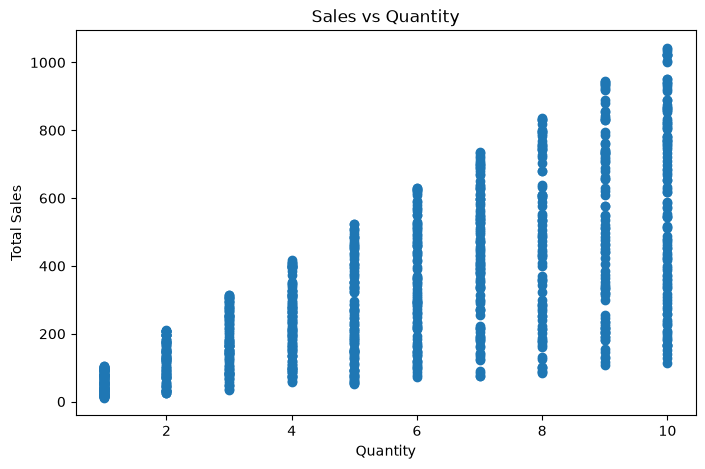

In [40]:
plt.figure(figsize=(8, 5))

plt.scatter(df["Quantity"], df["Total"])

plt.title("Sales vs Quantity")
plt.xlabel("Quantity")
plt.ylabel("Total Sales")

plt.show()

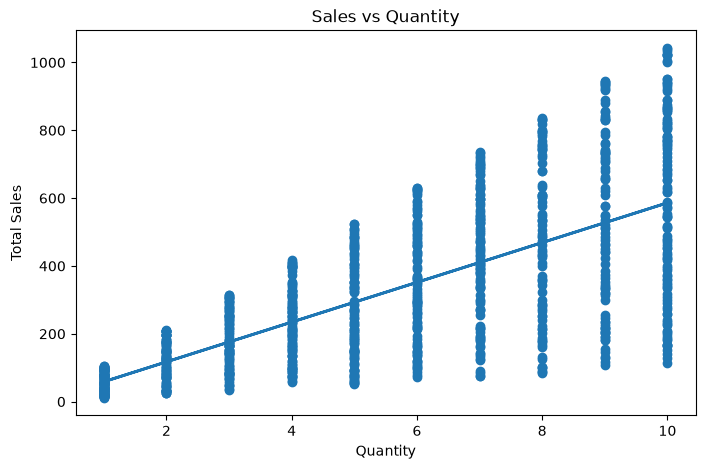

In [41]:
plt.figure(figsize=(8, 5))

plt.scatter(df["Quantity"], df["Total"])

plt.plot(
    df["Quantity"],
    df["Quantity"] * (df["Total"].mean() / df["Quantity"].mean()),
    linewidth=2
)

plt.title("Sales vs Quantity")
plt.xlabel("Quantity")
plt.ylabel("Total Sales")

plt.show()

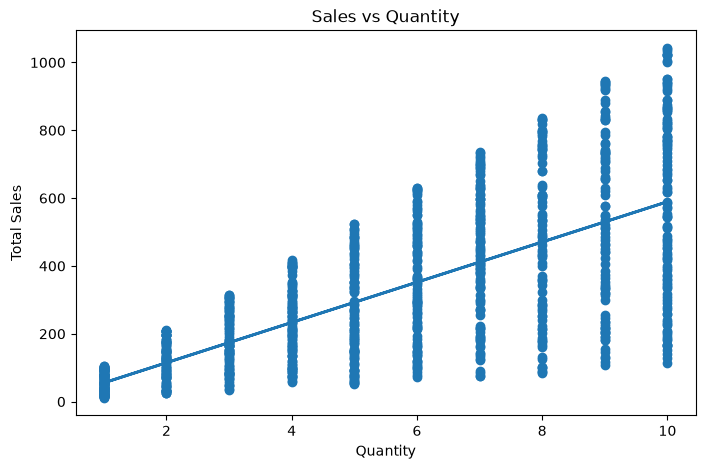

In [42]:
import numpy as np

x = df["Quantity"]
y = df["Total"]

slope, intercept = np.polyfit(x, y, 1)

trend_line = slope * x + intercept

plt.figure(figsize=(8, 5))

plt.scatter(x, y)
plt.plot(x, trend_line, linewidth=2)

plt.title("Sales vs Quantity")
plt.xlabel("Quantity")
plt.ylabel("Total Sales")

plt.show()

In [43]:
plt.savefig("../images/sales_vs_quantity.png", dpi=300, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>

In [44]:
avg_price = df.groupby("Product line")["Unit price"].mean()

print(avg_price)

Product line
Electronic accessories    53.551588
Fashion accessories       57.153652
Food and beverages        56.008851
Health and beauty         54.854474
Home and lifestyle        55.316937
Sports and travel         56.993253
Name: Unit price, dtype: float64


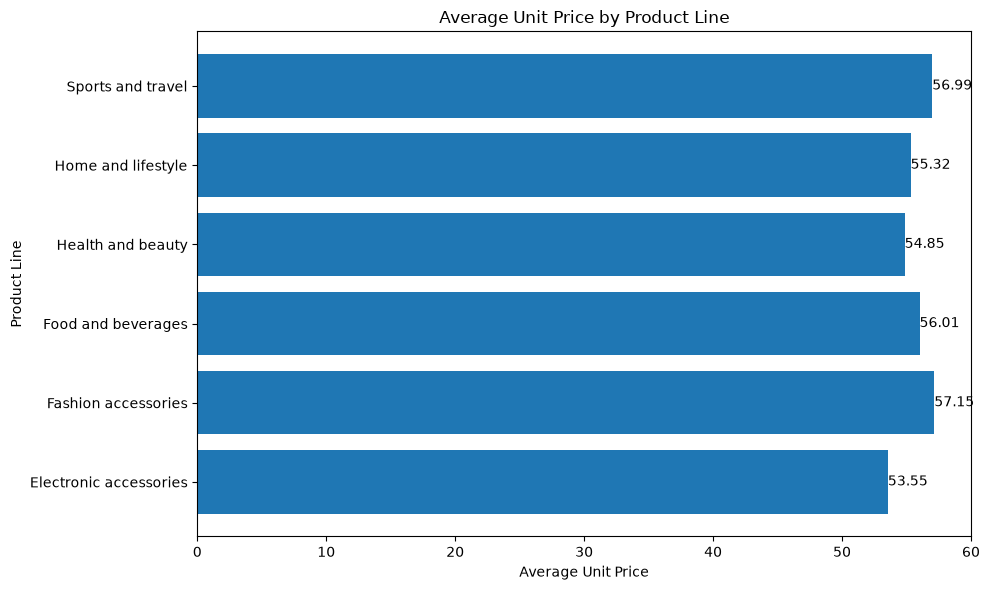

In [45]:
plt.figure(figsize=(10, 6))

bars = plt.barh(avg_price.index, avg_price.values)

plt.title("Average Unit Price by Product Line")
plt.xlabel("Average Unit Price")
plt.ylabel("Product Line")

for bar in bars:
    plt.text(
        bar.get_width(),
        bar.get_y() + bar.get_height() / 2,
        f"{bar.get_width():.2f}",
        va="center"
    )

plt.tight_layout()
plt.show()

In [46]:
plt.savefig("../images/avg_unit_price_by_product_line.png", dpi=300, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>

## 3. Distribution of Transaction Sales

This histogram shows how total sales values are distributed across individual transactions and helps identify common and unusually high transaction values.

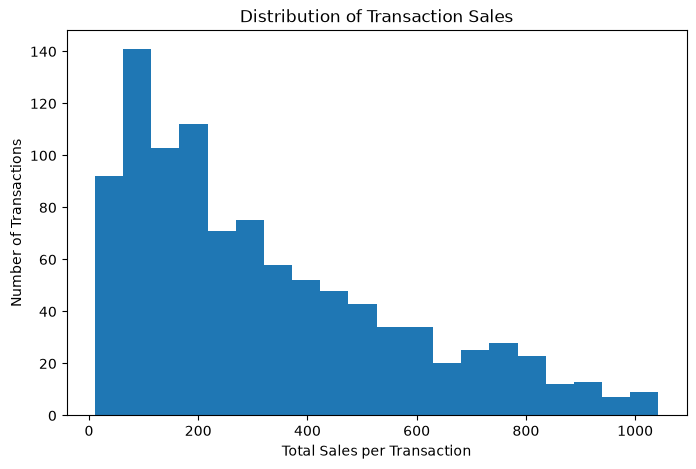

In [47]:
plt.figure(figsize=(8, 5))

plt.hist(df["Total"], bins=20)

plt.title("Distribution of Transaction Sales")
plt.xlabel("Total Sales per Transaction")
plt.ylabel("Number of Transactions")

plt.show()

In [48]:
plt.savefig("../images/transaction_sales_distribution.png", dpi=300, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>

## 4. Total Sales by Day of the Week

This visualization compares total sales across different days of the week and helps identify weekly sales patterns.

In [49]:
df["Day"] = df["Date"].dt.day_name()

print(df[["Date", "Day"]].head())

        Date       Day
0 2019-01-05  Saturday
1 2019-03-08    Friday
2 2019-03-03    Sunday
3 2019-01-27    Sunday
4 2019-02-08    Friday


In [50]:
day_sales = df.groupby("Day")["Total"].sum()

print(day_sales)

Day
Friday       43926.3405
Monday       37899.0780
Saturday     56120.8095
Sunday       44457.8925
Thursday     45349.2480
Tuesday      51482.2455
Wednesday    43731.1350
Name: Total, dtype: float64


In [51]:
day_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

day_sales = day_sales.reindex(day_order)

print(day_sales)

Day
Monday       37899.0780
Tuesday      51482.2455
Wednesday    43731.1350
Thursday     45349.2480
Friday       43926.3405
Saturday     56120.8095
Sunday       44457.8925
Name: Total, dtype: float64


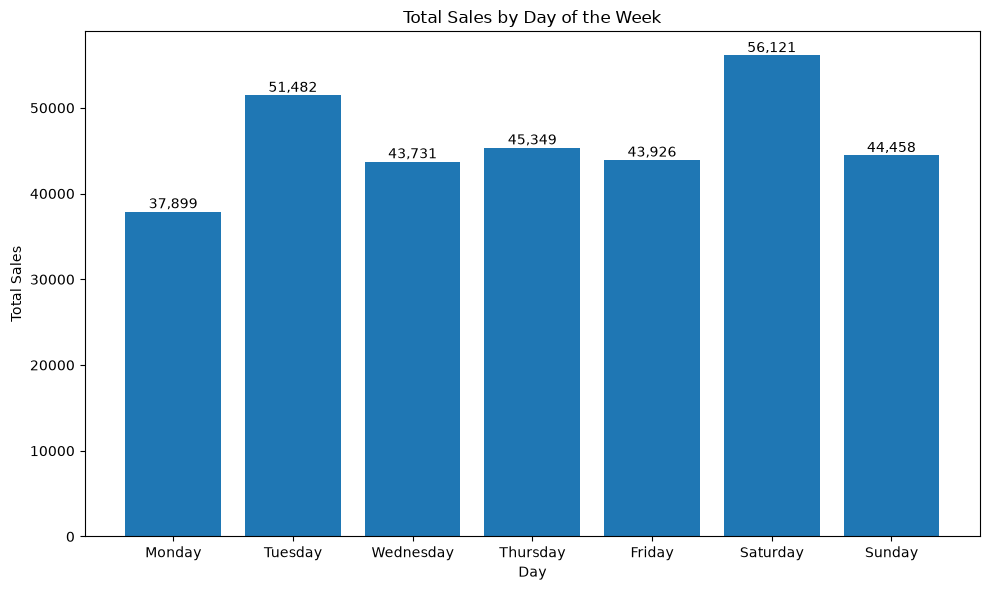

In [52]:
plt.figure(figsize=(10, 6))

bars = plt.bar(day_sales.index, day_sales.values)

plt.title("Total Sales by Day of the Week")
plt.xlabel("Day")
plt.ylabel("Total Sales")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{bar.get_height():,.0f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [53]:
plt.savefig("../images/sales_by_day_of_week.png", dpi=300, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>

## 5. Sales by Payment Method and Customer Type

This visualization compares sales across different payment methods and customer types.|

In [54]:
payment_customer = df.groupby(
    ["Payment", "Customer type"]
)["Total"].sum().unstack()

print(payment_customer)

Customer type      Member      Normal
Payment                              
Cash           54661.0155  57545.5545
Credit card    57771.4725  42995.5995
Ewallet        51790.9560  58202.1510


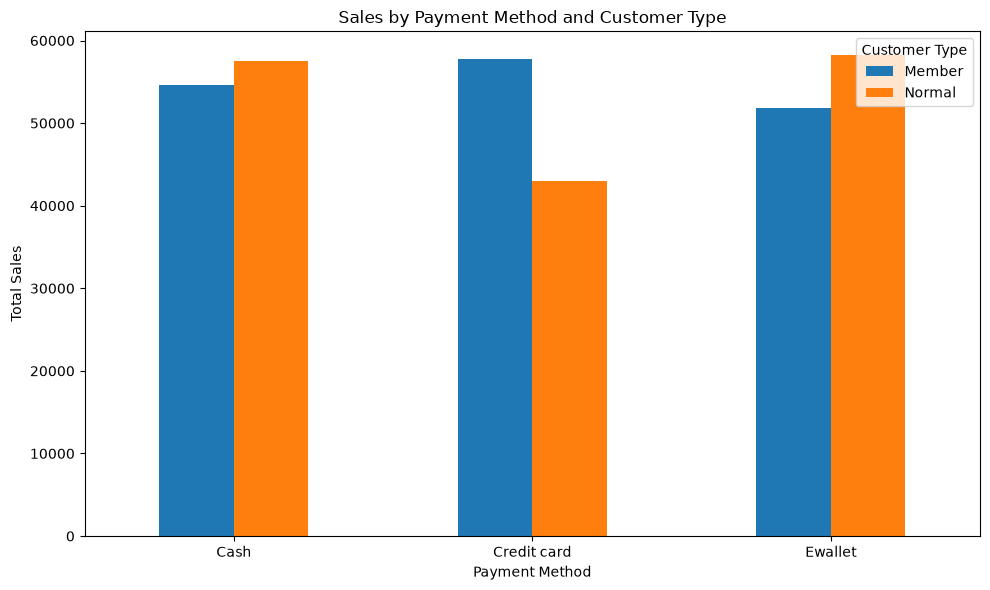

In [55]:
payment_customer.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Sales by Payment Method and Customer Type")
plt.xlabel("Payment Method")
plt.ylabel("Total Sales")

plt.xticks(rotation=0)
plt.legend(title="Customer Type")

plt.tight_layout()
plt.show()

In [56]:
plt.savefig("../images/payment_vs_customer_type.png", dpi=300, bbox_inches="tight")


<Figure size 640x480 with 0 Axes>

## 6. Correlation Between Numerical Variables

This heatmap shows the relationships between numerical variables in the dataset using correlation values.

In [57]:
numeric_data = df[
    [
        "Unit price",
        "Quantity",
        "Tax 5%",
        "Total",
        "Cost of goods sold",
        "Gross income",
        "Customer stratification rating"
    ]
]

correlation = numeric_data.corr()

print(correlation)

                                Unit price  Quantity    Tax 5%     Total  \
Unit price                        1.000000  0.010778  0.633962  0.633962   
Quantity                          0.010778  1.000000  0.705510  0.705510   
Tax 5%                            0.633962  0.705510  1.000000  1.000000   
Total                             0.633962  0.705510  1.000000  1.000000   
Cost of goods sold                0.633962  0.705510  1.000000  1.000000   
Gross income                      0.633962  0.705510  1.000000  1.000000   
Customer stratification rating   -0.008778 -0.015815 -0.036442 -0.036442   

                                Cost of goods sold  Gross income  \
Unit price                                0.633962      0.633962   
Quantity                                  0.705510      0.705510   
Tax 5%                                    1.000000      1.000000   
Total                                     1.000000      1.000000   
Cost of goods sold                        1.000000 

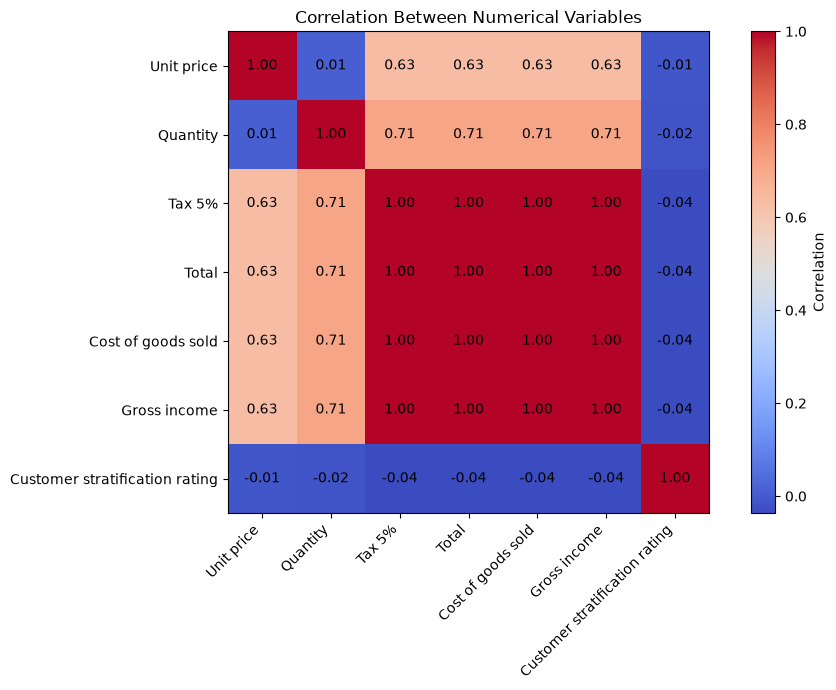

In [58]:
plt.figure(figsize=(10, 7))

plt.imshow(correlation, cmap="coolwarm")

plt.colorbar(label="Correlation")

plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(correlation.columns)),
    correlation.columns
)

plt.title("Correlation Between Numerical Variables")

for i in range(len(correlation.columns)):
    for j in range(len(correlation.columns)):
        plt.text(
            j,
            i,
            f"{correlation.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )

plt.tight_layout()
plt.show()

In [59]:
plt.savefig("../images/correlation_heatmap.png", dpi=300, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>

## 7. Average Sales by Customer Type

This visualization compares the average sales value per transaction for different customer types.

In [60]:
avg_customer_sales = df.groupby("Customer type")["Total"].mean()

print(avg_customer_sales)

Customer type
Member    327.791305
Normal    318.122856
Name: Total, dtype: float64


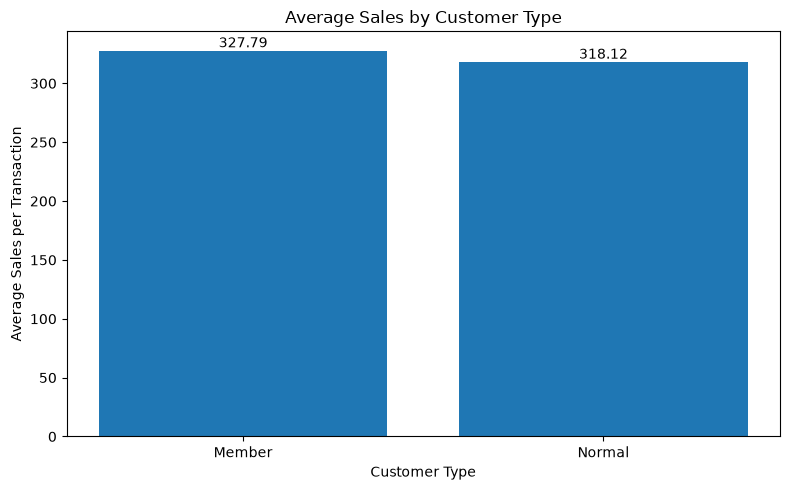

In [61]:
plt.figure(figsize=(8, 5))

bars = plt.bar(
    avg_customer_sales.index,
    avg_customer_sales.values
)

plt.title("Average Sales by Customer Type")
plt.xlabel("Customer Type")
plt.ylabel("Average Sales per Transaction")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{bar.get_height():.2f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [62]:
plt.savefig("../images/average_sales_by_customer_type.png", dpi=300, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>

## 8. Average Sales by Gender

This visualization compares the average sales value per transaction between different genders.

In [63]:
avg_gender_sales = df.groupby("Gender")["Total"].mean()

print(avg_gender_sales)

Gender
Female    335.095659
Male      310.789226
Name: Total, dtype: float64


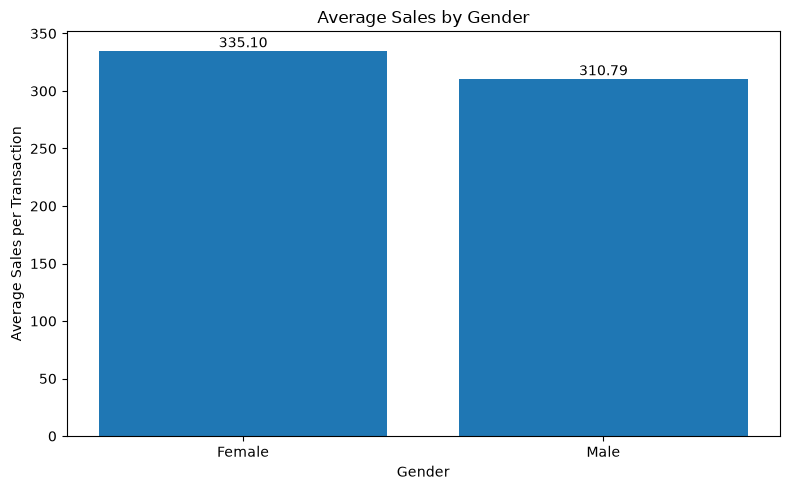

In [64]:
plt.figure(figsize=(8, 5))

bars = plt.bar(
    avg_gender_sales.index,
    avg_gender_sales.values
)

plt.title("Average Sales by Gender")
plt.xlabel("Gender")
plt.ylabel("Average Sales per Transaction")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{bar.get_height():.2f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [65]:
plt.savefig("../images/average_sales_by_gender.png", dpi=300, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>

## 9. Distribution of Quantity per Transaction

This histogram shows how many products customers typically purchase in a single transaction.

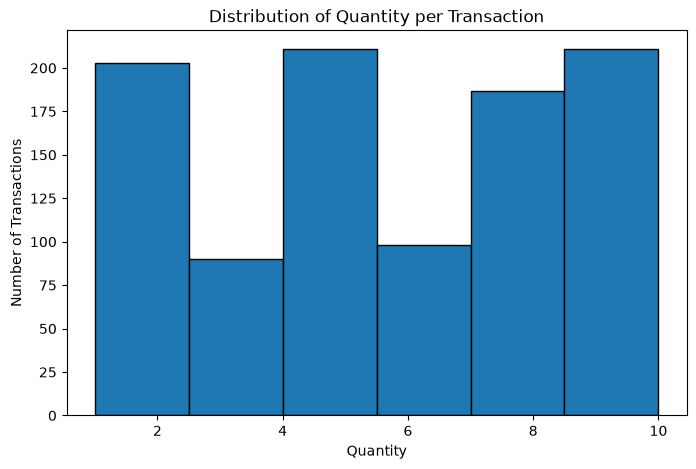

In [66]:
plt.figure(figsize=(8, 5))

plt.hist(df["Quantity"], bins=6, edgecolor="black")

plt.title("Distribution of Quantity per Transaction")
plt.xlabel("Quantity")
plt.ylabel("Number of Transactions")

plt.show()

In [67]:
plt.savefig("../images/quantity_distribution.png", dpi=300, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>

## 10. Sales vs Gross Income

This visualization shows the relationship between total sales and gross income for individual transactions.

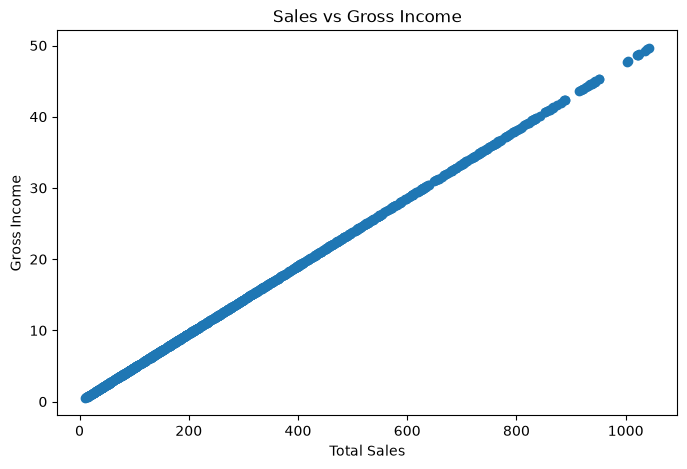

In [68]:
plt.figure(figsize=(8, 5))

plt.scatter(df["Total"], df["Gross income"])

plt.title("Sales vs Gross Income")
plt.xlabel("Total Sales")
plt.ylabel("Gross Income")

plt.show()

In [69]:
plt.savefig("../images/sales_vs_gross_income.png", dpi=300, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>

## Key Insights

- Sales generally increase as the quantity of products in a transaction increases.
- Average unit prices vary across different product lines.
- Transaction sales are concentrated within a common range, with some higher-value transactions.
- Sales vary across different days of the week.
- Payment methods show different sales patterns across customer types.
- Total sales and gross income show a strong positive relationship.
- Customer type and gender can be compared using average transaction sales.
- Most transactions contain a relatively small number of products.